# 勾配降下法による学習の実装

**勾配降下法によるパラメータ学習の実装**です。次の3つの問題で、損失と予測結果を比較します。

- **一次関数の係数推定**（線形回帰）
- **線形分離可能な 2 クラス分類**（ロジスティック回帰）
- **ドーナツ状パターンの非線形分類**（ニューラルネットワーク）

各問題で損失関数の偏微分とパラメータ更新のコードを示します。偏微分を自分で導出してから、式と照合することもできます。

In [1]:
!pip install -q numpy  # 数値計算（配列・行列演算）
!pip install -q matplotlib  # グラフの描画
!pip install -q japanize_matplotlib  # matplotlib のグラフを日本語表示にする

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 52.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


---

## 一次関数の係数推定（線形回帰）

真の関数 $y = 2x + 1$ にノイズを加えたデータ点 $(x_i, y_i)$ を生成し、平均二乗誤差（MSE）を最小化することで $a, b$ を推定します。

損失関数：

$$\hat{y}_i = a x_i + b, \qquad L = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)^2$$

ここで $n$ はデータ数、$\hat{y}_i$ は予測値、$L$ は予測と実測のずれを表す損失です。勾配降下法では、損失を各パラメータで偏微分した値に学習率を掛け、その分をパラメータから引きます。

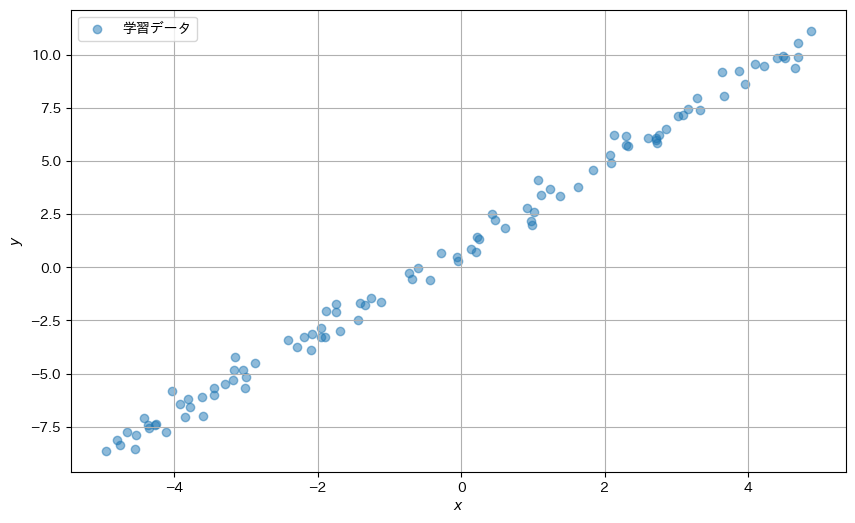

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import japanize_matplotlib  # import するだけで図の日本語表示が有効になる

# 真のパラメータ
true_a = 2.0
true_b = 1.0

# データ点の生成
np.random.seed(42)
x = np.random.uniform(-5, 5, 100)
y = true_a * x + true_b + np.random.normal(0, 0.5, 100)

# 散布図でデータを可視化
plt.figure(figsize=(10, 6))
plt.scatter(x, y, alpha=0.5, label="学習データ")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.grid(True)
plt.show()

点はおおむね直線上に並んでいますが、加えたノイズのぶんだけ上下にばらついています。この点群から、もとの直線の $a, b$ を当てるのが目標です。


### モデルと学習

学習したパラメータ $a, b$ は `LinearModel` にまとめ、予測は `model.predict(x)` で行います。
予測に必要な係数は `reg.a` と `reg.b`、損失の履歴は `reg_losses` として取り出せます。

損失 $L$ の偏微分を手で導出すると、次のようになります（これを更新式に用います）：

$$\frac{\partial L}{\partial a} = \frac{2}{n}\sum_i (\hat{y}_i - y_i)\,x_i, \qquad \frac{\partial L}{\partial b} = \frac{2}{n}\sum_i (\hat{y}_i - y_i)$$

In [3]:
from dataclasses import dataclass


@dataclass
class LinearModel:
    """学習済みの一次関数モデル。傾き a と切片 b を保持し、予測に使う。"""

    a: float
    b: float

    def predict(self, x: np.ndarray) -> np.ndarray:
        return self.a * x + self.b


def train_linear_regression(
    x: np.ndarray,
    y: np.ndarray,
    learning_rate: float = 0.01,
    n_epochs: int = 200,
    seed: int = 42,
) -> tuple[LinearModel, list[float]]:
    """勾配降下法で一次関数 y = ax + b の係数を推定し、モデルと損失の履歴を返す。"""
    np.random.seed(seed)
    a = np.random.randn()
    b = np.random.randn()
    losses = []
    log_interval = max(1, n_epochs // 10)  # 何エポックおきに表示するか

    for epoch in range(n_epochs):
        y_pred = a * x + b
        loss = np.mean((y_pred - y) ** 2)
        losses.append(loss)

        # 手で導出した勾配
        error = y_pred - y
        grad_a = np.mean(2 * error * x)
        grad_b = np.mean(2 * error)

        a -= learning_rate * grad_a
        b -= learning_rate * grad_b

        if (epoch + 1) % log_interval == 0:
            print(f"Epoch {epoch + 1}: loss = {loss:.4f}, a = {a:.4f}, b = {b:.4f}")

    return LinearModel(a=a, b=b), losses


reg, reg_losses = train_linear_regression(x, y, learning_rate=0.01, n_epochs=200)

Epoch 20: loss = 0.8639, a = 1.9179, b = 0.1987
Epoch 40: loss = 0.4946, a = 1.9562, b = 0.4594
Epoch 60: loss = 0.3334, a = 1.9634, b = 0.6350
Epoch 80: loss = 0.2609, a = 1.9679, b = 0.7528
Epoch 100: loss = 0.2283, a = 1.9709, b = 0.8317
Epoch 120: loss = 0.2136, a = 1.9729, b = 0.8847
Epoch 140: loss = 0.2070, a = 1.9743, b = 0.9202
Epoch 160: loss = 0.2041, a = 1.9752, b = 0.9441
Epoch 180: loss = 0.2027, a = 1.9758, b = 0.9601
Epoch 200: loss = 0.2021, a = 1.9762, b = 0.9708


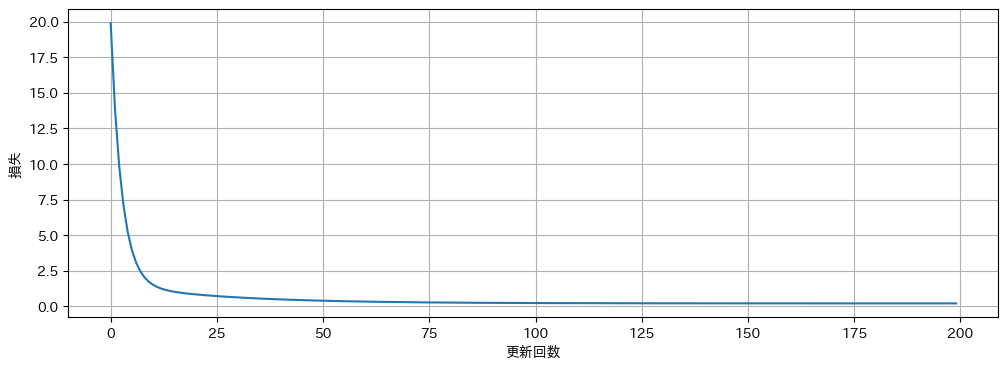

学習結果: a = 1.9762, b = 0.9708
真の値:   a = 2.0000, b = 1.0000


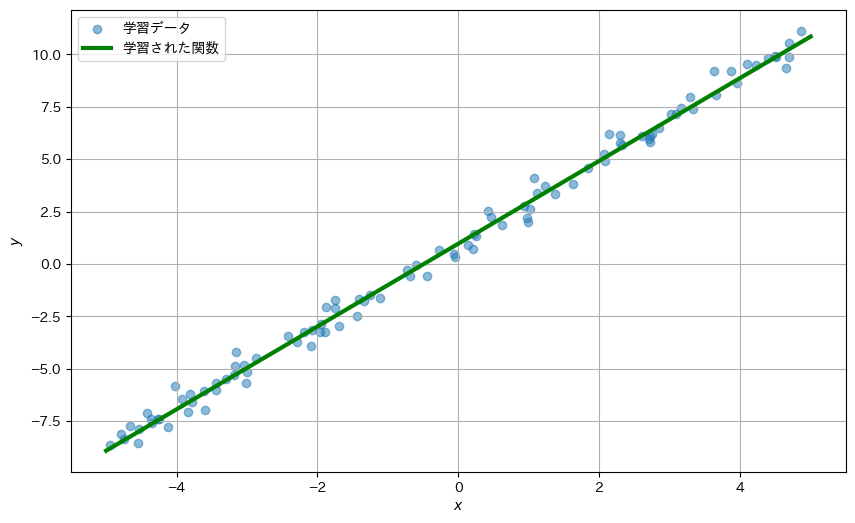

In [4]:
# 損失の推移
plt.figure(figsize=(12, 4))
plt.plot(reg_losses)
plt.xlabel("更新回数")
plt.ylabel("損失")
plt.grid(True)
plt.show()

# 学習後の結果と真の値を比較
print(f"学習結果: a = {reg.a:.4f}, b = {reg.b:.4f}")
print(f"真の値:   a = {true_a:.4f}, b = {true_b:.4f}")

# 学習された直線を可視化
plt.figure(figsize=(10, 6))
plt.scatter(x, y, alpha=0.5, label="学習データ")
plt.plot(
    [-5, 5], reg.predict(np.array([-5, 5])), "g-", label="学習された関数", linewidth=3
)
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.grid(True)
plt.show()

データにはノイズがあるため、損失が 0 まで下がることはありませんが、一定のところで下げ止まります。推定値は真の値 $(2, 1)$ に近く、データによく合う直線が得られました。



### 失敗例：学習率が大きすぎる場合

学習率を極端に大きく設定すると、パラメータが更新のたびに行き過ぎて発散し、損失が増加します。実際に確認しましょう。

Epoch 5: loss = 111855683186.2525, a = 1877517.6845, b = -71211.4910
Epoch 10: loss = 191388739883165066199040.0000, a = -2455911619867.1865, b = 93151905702.7468
Epoch 15: loss = 327472406507219406885355269616828416.0000, a = 3212490840574183424.0000, b = -121848702303013296.0000
Epoch 20: loss = 560316020101778435573748648606567157207960387584.0000, a = -4202145271548075206246400.0000, b = 159385963614252541411328.0000
Epoch 25: loss = 958719074169613646625331804685652553022435958279241182740480.0000, a = 5496677114272409109591398285312.0000, b = -208487123105090327854924693504.0000
Epoch 30: loss = 1640399756925891165332483944436681998681644355679321718850369463905157120.0000, a = -7190008280564600583769707383663624192.0000, b = 272714607453364379409110478996111360.0000
Epoch 35: loss = 2806777746498087994397746591302118957050511680838843593442126894988811509522581422080.0000, a = 9404994690402239735025251187657488346382336.0000, b = -356728300581680753136999425039539019710464.0000


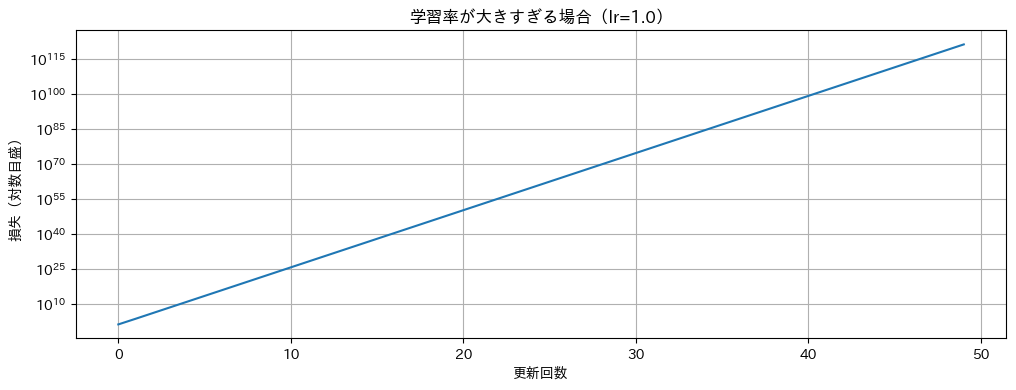

In [5]:
# 学習率を大きくして発散を確認
_, diverged_losses = train_linear_regression(x, y, learning_rate=1.0, n_epochs=50)

plt.figure(figsize=(12, 4))
plt.plot(diverged_losses)
plt.yscale("log")  # 損失が急激に増えるので対数目盛にする
plt.xlabel("更新回数")
plt.ylabel("損失（対数目盛）")
plt.title("学習率が大きすぎる場合（lr=1.0）")
plt.grid(True)
plt.show()

縦軸は対数目盛です。損失は1回目の更新から一貫して増え続けています。学習率は「大きいほど速く学習する」わけではなく、大きすぎると学習そのものが破綻することがわかります。

---

## 線形分離可能な 2 クラス分類（ロジスティック回帰）

2 次元平面上に線形分離可能な 2 クラスのデータを生成し、シグモイド関数と交差エントロピー損失で分類境界を学習します。

入力の重み付き和にシグモイド関数を適用して2値分類を行うモデルを、**ロジスティック回帰**と呼びます。シグモイド関数 $\sigma$ は値を0〜1に変換し、クラス1である予測確率 $\hat{y}$ として扱います。正解ラベル $y$ は0または1です。

$$\hat{y} = \sigma(\mathbf{x}\mathbf{w}^\top + b), \quad \sigma(z) = \frac{1}{1+e^{-z}}$$

$$L = -\frac{1}{n}\sum_{i=1}^{n}\left[y_i \log \hat{y}_i + (1 - y_i)\log(1-\hat{y}_i)\right]$$

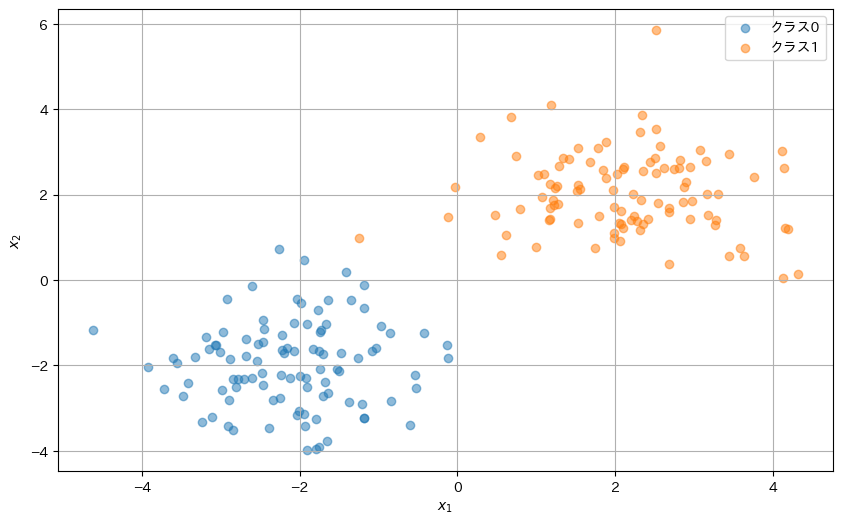

In [6]:
# 線形分離可能な 2 クラスのデータを生成
np.random.seed(42)
n_samples = 100

# クラス0（左下）と クラス1（右上）
X_class0 = np.random.normal(-2, 1, (n_samples, 2))
X_class1 = np.random.normal(2, 1, (n_samples, 2))

X = np.vstack([X_class0, X_class1])
y_cls = np.hstack([np.zeros(n_samples), np.ones(n_samples)])

# 散布図でクラスごとに色分けして表示
plt.figure(figsize=(10, 6))
plt.scatter(
    X_class0[:, 0], X_class0[:, 1], alpha=0.5, label="クラス0", color="tab:blue"
)
plt.scatter(
    X_class1[:, 0], X_class1[:, 1], alpha=0.5, label="クラス1", color="tab:orange"
)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.legend()
plt.grid(True)
plt.show()

2 つのクラスは左下と右上にはっきり分かれており、1 本の直線で分離できそうです。


### モデルと学習

線形回帰と同じく、学習結果を `LogisticModel` にまとめます。予測確率は `model.predict_proba(X)` で得られます。
`sigmoid` はこの後も使う共通の関数です。

損失 $L$ の偏微分（$n$ はデータ数）：

$$\frac{\partial L}{\partial \mathbf{w}} = \frac{1}{n}\sum_i (\hat{y}_i - y_i)\,\mathbf{x}_i, \qquad \frac{\partial L}{\partial b} = \frac{1}{n}\sum_i (\hat{y}_i - y_i)$$

Epoch 10: loss = 0.1489
Epoch 20: loss = 0.0913
Epoch 30: loss = 0.0685
Epoch 40: loss = 0.0560
Epoch 50: loss = 0.0481


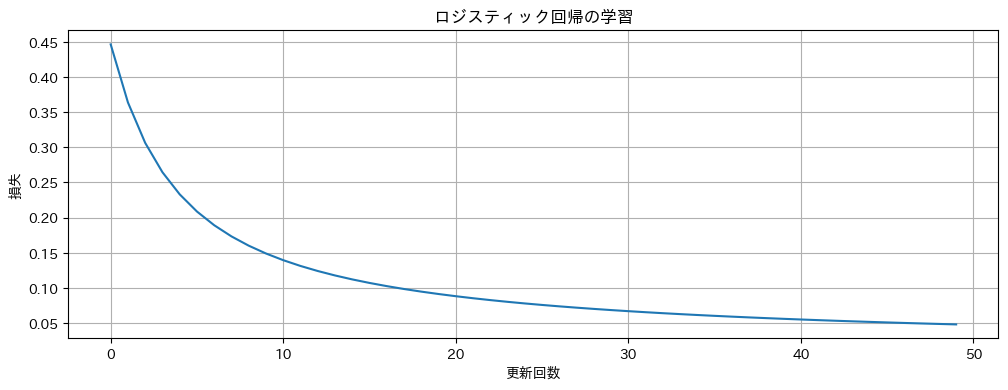

In [7]:
def sigmoid(z: np.ndarray) -> np.ndarray:
    """シグモイド関数。任意の実数を 0〜1 の範囲に押し込める。"""
    return 1 / (1 + np.exp(-z))


@dataclass
class LogisticModel:
    """学習済みのロジスティック回帰モデル。重み w とバイアス b を保持する。"""

    w: np.ndarray
    b: float

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        # `@` は行列積
        return sigmoid(X @ self.w + self.b)


def train_logistic_regression(
    X: np.ndarray,
    y: np.ndarray,
    learning_rate: float = 0.1,
    n_epochs: int = 50,
    seed: int = 42,
) -> tuple[LogisticModel, list[float]]:
    """勾配降下法でロジスティック回帰を学習し、モデルと損失の履歴を返す。"""
    np.random.seed(seed)
    w = np.random.randn(X.shape[1])
    b = np.random.randn()
    losses = []

    for epoch in range(n_epochs):
        y_pred = sigmoid(X @ w + b)

        # 交差エントロピー損失
        epsilon = 1e-15
        loss = -np.mean(
            y * np.log(y_pred + epsilon) + (1 - y) * np.log(1 - y_pred + epsilon)
        )
        losses.append(loss)

        # 手で導出した勾配
        error = y_pred - y
        grad_w = (error[:, np.newaxis] * X).mean(axis=0)
        grad_b = error.mean()

        w -= learning_rate * grad_w
        b -= learning_rate * grad_b

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch + 1}: loss = {loss:.4f}")

    return LogisticModel(w=w, b=b), losses


clf, clf_losses = train_logistic_regression(X, y_cls, learning_rate=0.1, n_epochs=50)

plt.figure(figsize=(12, 4))
plt.plot(clf_losses)
plt.xlabel("更新回数")
plt.ylabel("損失")
plt.title("ロジスティック回帰の学習")
plt.grid(True)
plt.show()

### 決定境界を描く共通の関数

決定境界の可視化（平面を格子で覆い、各点の予測確率を色で塗る処理）は、このあと非線形分類でも繰り返し使います。定型処理なので 1 つの関数にまとめておき、モデルの `predict_proba` を渡すだけで境界を描けるようにします。

塗りの色は予測確率を表します。濃いオレンジは「クラス1 である確率が高い」、濃い青は「クラス0 である確率が高い」、その境目の白い帯が確率 0.5 の決定境界です。境界線そのものは描かれないので、白い帯の位置を境界として読んでください。

In [8]:
from collections.abc import Callable

from matplotlib.axes import Axes
from matplotlib.colors import LinearSegmentedColormap


def plot_decision_boundary(
    predict_proba: Callable[[np.ndarray], np.ndarray],
    X_a: np.ndarray,
    X_b: np.ndarray,
    labels: list[str],
    title: str,
    ax: Axes | None = None,
) -> None:
    """予測関数を受け取り、2クラスの予測確率とデータ点を描く。"""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 6))

    points = np.vstack([X_a, X_b])
    x1_min, x1_max = points[:, 0].min() - 1, points[:, 0].max() + 1
    x2_min, x2_max = points[:, 1].min() - 1, points[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(
        np.linspace(x1_min, x1_max, 100), np.linspace(x2_min, x2_max, 100)
    )
    grid = np.column_stack([xx1.ravel(), xx2.ravel()])
    proba = predict_proba(grid).reshape(xx1.shape)

    cmap = LinearSegmentedColormap.from_list(
        "BlueOrange", ["tab:blue", "white", "tab:orange"]
    )
    ax.pcolormesh(xx1, xx2, proba, cmap=cmap, vmin=0, vmax=1, alpha=0.3, shading="auto")
    ax.scatter(X_a[:, 0], X_a[:, 1], alpha=0.5, label=labels[0], color="tab:blue")
    ax.scatter(X_b[:, 0], X_b[:, 1], alpha=0.5, label=labels[1], color="tab:orange")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(title)
    ax.legend()
    ax.grid(True)

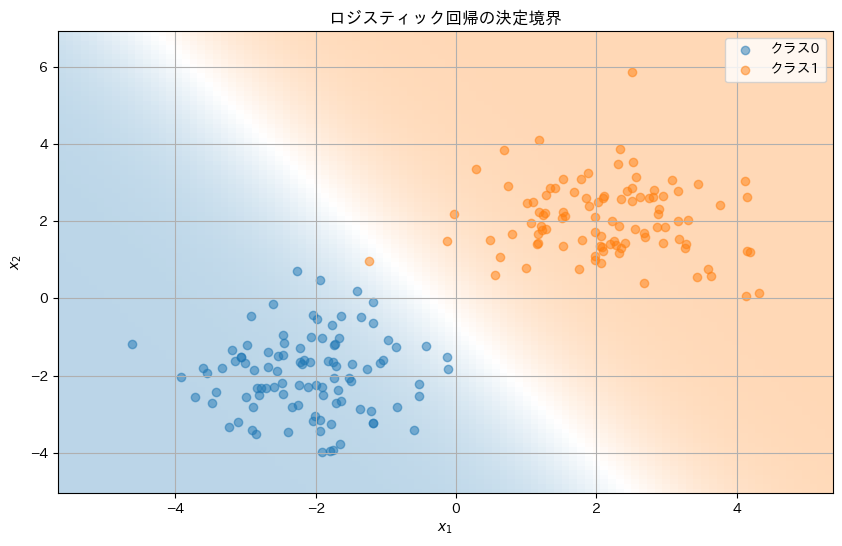

In [9]:
plot_decision_boundary(
    clf.predict_proba,
    X_class0,
    X_class1,
    ["クラス0", "クラス1"],
    "ロジスティック回帰の決定境界",
)
plt.show()

直線状の境界で 2 クラスをきれいに分離できています。線形分離可能なデータなら、この単純なモデルで十分です。

## ドーナツ状パターンの非線形分類（ニューラルネットワーク）

内側の円（半径1）と外側のリング（半径2.5）に分布する2クラスのデータは、直線では分離できません。線形変換の間にシグモイド関数という非線形な変換を挟み、曲がった決定境界を学習します。

ここで実装するのは、**二層ニューラルネットワーク**です。1層目が作る10個の値を隠れ層のベクトル $\mathbf{h}_1$ とし、2層目でクラス1の確率を求めます。

$$\mathbf{h}_1 = \sigma(\mathbf{x}\mathbf{W}_1 + \mathbf{b}_1), \quad \hat{y} = \sigma(\mathbf{h}_1\mathbf{w}_2^\top + b_2)$$

1層目の重み $\mathbf{W}_1$ は行列、2層目の重み $\mathbf{w}_2$ はベクトル、バイアス $b_2$ は1つの数値です。コードでは行列積の形をそろえるため、2層目の重みを形 `(hidden_dim, 1)` の配列 `W2` として扱います。`hidden_dim` が隠れ層の次元です。`@` は行列積、`.T` は行と列の入れ替えを表します。

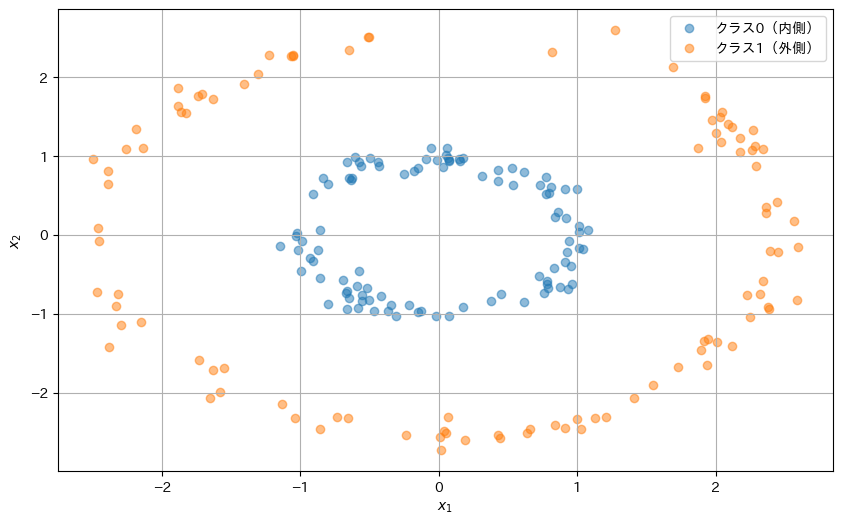

In [10]:
# ドーナツ状データの生成
np.random.seed(42)
n_samples = 100

# 内側の円（クラス0）：半径 1
radius0 = np.random.normal(1, 0.1, n_samples)
theta0 = np.random.uniform(0, 2 * np.pi, n_samples)
X_inner = np.column_stack([radius0 * np.cos(theta0), radius0 * np.sin(theta0)])

# 外側のリング（クラス1）：半径 2.5
radius1 = np.random.normal(2.5, 0.1, n_samples)
theta1 = np.random.uniform(0, 2 * np.pi, n_samples)
X_outer = np.column_stack([radius1 * np.cos(theta1), radius1 * np.sin(theta1)])

X_donut = np.vstack([X_inner, X_outer])
y_donut = np.hstack([np.zeros(n_samples), np.ones(n_samples)])

# 散布図でクラスごとに色分けして表示
plt.figure(figsize=(10, 6))
plt.scatter(X_inner[:, 0], X_inner[:, 1], alpha=0.5, label="クラス0（内側）")
plt.scatter(X_outer[:, 0], X_outer[:, 1], alpha=0.5, label="クラス1（外側）")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.legend()
plt.grid(True)
plt.show()

内側と外側の 2 重のリングになっています。どこに直線を引いても 2 クラスを分けられないことが、図から見てとれます。


### 失敗例：線形モデルで非線形データを分類する

まず、先ほどのロジスティック回帰をそのままドーナツデータに適用し、直線では分離できないことを確認します。`train_logistic_regression` はデータを変えるだけでそのまま使えます。

Epoch 10: loss = 0.7328
Epoch 20: loss = 0.7109
Epoch 30: loss = 0.6986
Epoch 40: loss = 0.6919
Epoch 50: loss = 0.6881


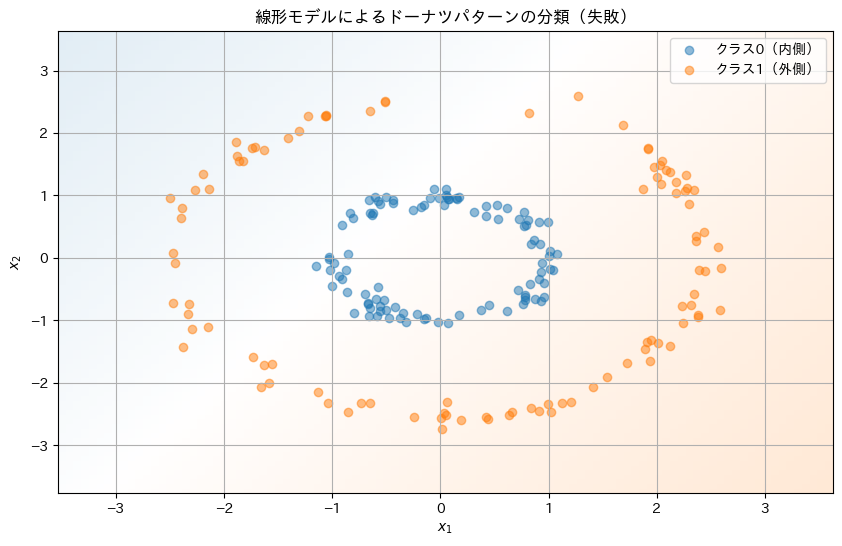

In [11]:
clf_donut, _ = train_logistic_regression(
    X_donut, y_donut, learning_rate=0.1, n_epochs=50
)

plot_decision_boundary(
    clf_donut.predict_proba,
    X_inner,
    X_outer,
    ["クラス0（内側）", "クラス1（外側）"],
    "線形モデルによるドーナツパターンの分類（失敗）",
)
plt.show()

損失は 0.69 付近から下がりません。これは 2 クラスを五分五分（確率 0.5）と予測したときの損失$-\log 0.5 \approx 0.693$ にあたり、この分類に役立つ予測ができていないことが分かります。

境界は直線にしかならず、内側と外側を分けられていません。線形モデルの表現力の限界がはっきり見えます。


### ニューラルネットワークによる非線形分類

隠れ層にシグモイド活性化関数を導入すると、非線形な決定境界を獲得できます。順伝播・逆伝播を手動で実装しましょう。学習結果は `NNModel` にまとめ、予測は `model.predict_proba(X)` で行います。

逆伝播では、合成関数の微分（連鎖律）を使って、出力側から入力側へ順に勾配を伝えます。途中でシグモイドの微分 $\sigma'(z) = \sigma(z)(1 - \sigma(z))$ を使う点だけ補っておきます（コード中の `h * (1 - h)` がこれにあたります）。

勾配の平均の取り方に一点だけ注意があります。コードでは $\partial L/\partial z_2$ を求める行で`/ len(X)` とデータ数で割っています。損失が全データの平均だからです。以降の層ではこの値を使い回すだけなので、改めて平均を取る必要はありません（ロジスティック回帰では最後に `.mean(axis=0)` を取っていましたが、割る場所が違うだけで同じことをしています）。

非線形な境界の学習は線形モデルより難しく、収束までに多くの更新が必要です。ここでは学習率 0.5・3000 回の更新を使います。この値を変えるとどうなるかは、最後の「実験してみましょう」で試せます。


Epoch 300: loss = 0.2471
Epoch 600: loss = 0.0830
Epoch 900: loss = 0.0421
Epoch 1200: loss = 0.0265
Epoch 1500: loss = 0.0188
Epoch 1800: loss = 0.0143
Epoch 2100: loss = 0.0115
Epoch 2400: loss = 0.0096
Epoch 2700: loss = 0.0082
Epoch 3000: loss = 0.0071


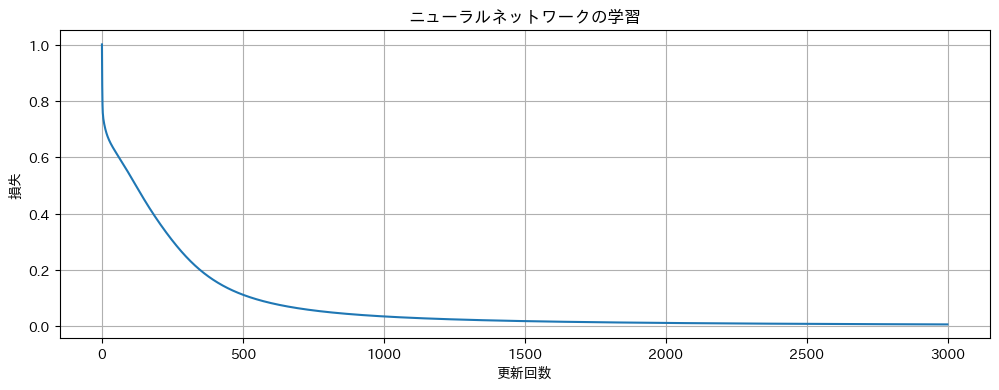

In [12]:
@dataclass
class NNModel:
    """学習済みの 1 隠れ層ニューラルネットワーク。各層の重みとバイアスを保持する。"""

    W1: np.ndarray
    b1: np.ndarray
    W2: np.ndarray
    b2: np.ndarray

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        h = sigmoid(X @ self.W1 + self.b1)
        return sigmoid(h @ self.W2 + self.b2)


def train_neural_network(
    X: np.ndarray,
    y: np.ndarray,
    hidden_dim: int = 10,
    learning_rate: float = 0.5,
    n_epochs: int = 3000,
    seed: int = 42,
) -> tuple[NNModel, list[float]]:
    """1 隠れ層のニューラルネットワークを勾配降下法で学習し、モデルと損失の履歴を返す。"""
    np.random.seed(seed)
    input_dim = X.shape[1]
    y_target = y[:, None]

    W1 = np.random.randn(input_dim, hidden_dim)
    b1 = np.zeros(hidden_dim)
    W2 = np.random.randn(hidden_dim, 1)
    b2 = np.zeros(1)

    losses = []
    log_interval = max(1, n_epochs // 10)

    for epoch in range(n_epochs):
        # --- 順伝播 ---
        h = sigmoid(X @ W1 + b1)
        y_hat = sigmoid(h @ W2 + b2)

        # 交差エントロピー損失
        epsilon = 1e-15
        loss = -np.mean(
            y_target * np.log(y_hat + epsilon)
            + (1 - y_target) * np.log(1 - y_hat + epsilon)
        )
        losses.append(loss)

        # --- 逆伝播（手で導出した勾配）---
        dz2 = (y_hat - y_target) / len(X)
        dW2 = h.T @ dz2
        db2 = dz2.sum(axis=0)

        dh = dz2 @ W2.T
        dz1 = dh * h * (1 - h)
        dW1 = X.T @ dz1
        db1 = dz1.sum(axis=0)

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        if (epoch + 1) % log_interval == 0:
            print(f"Epoch {epoch + 1}: loss = {loss:.4f}")

    return NNModel(W1=W1, b1=b1, W2=W2, b2=b2), losses


nn, nn_losses = train_neural_network(
    X_donut, y_donut, hidden_dim=10, learning_rate=0.5, n_epochs=3000
)

plt.figure(figsize=(12, 4))
plt.plot(nn_losses)
plt.xlabel("更新回数")
plt.ylabel("損失")
plt.title("ニューラルネットワークの学習")
plt.grid(True)
plt.show()

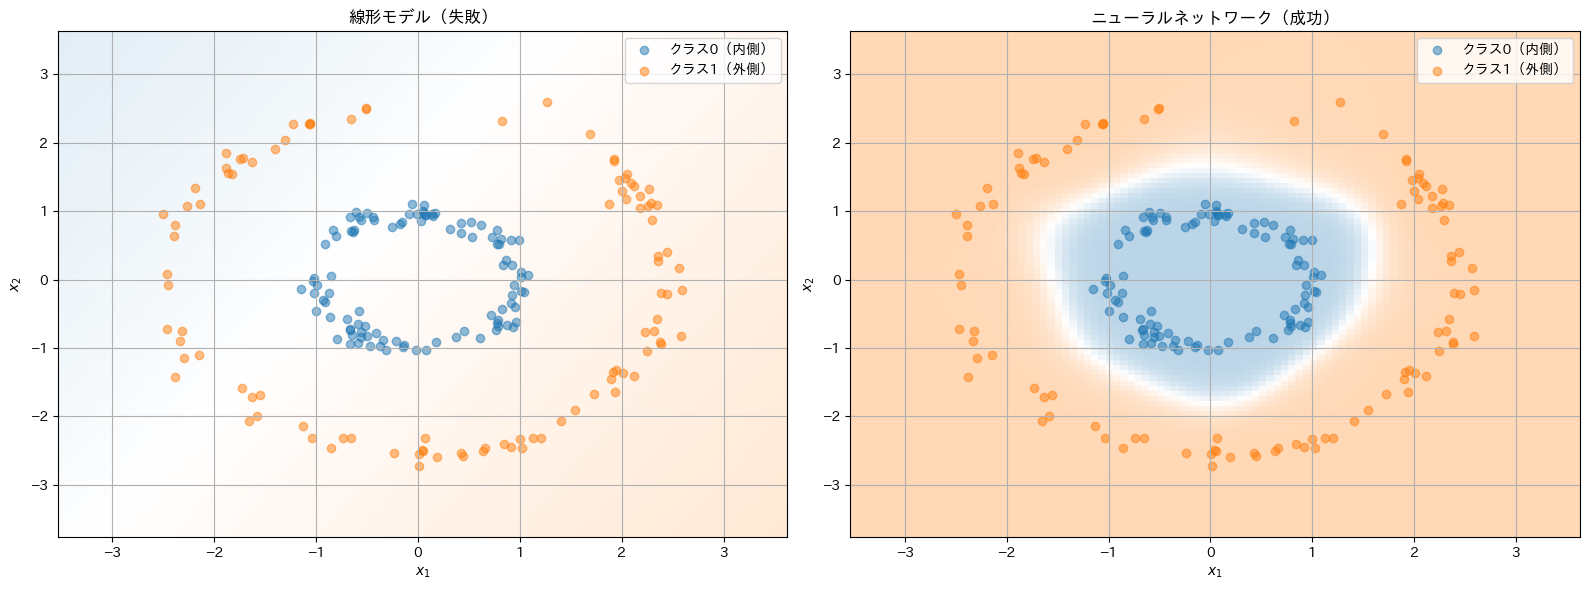

In [13]:
# 線形モデル（失敗）とニューラルネットワーク（成功）を並べて比較
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
labels = ["クラス0（内側）", "クラス1（外側）"]

plot_decision_boundary(
    clf_donut.predict_proba, X_inner, X_outer, labels, "線形モデル（失敗）", ax=axes[0]
)
plot_decision_boundary(
    nn.predict_proba,
    X_inner,
    X_outer,
    labels,
    "ニューラルネットワーク（成功）",
    ax=axes[1],
)

plt.tight_layout()
plt.show()

線形モデルの境界は直線のままですが、ニューラルネットワークは内側の円を囲む曲線状の境界を学習し、2 クラスを正しく分離できています。隠れ層と活性化関数を重ねることで、直線では表せない境界が獲得できることが目で確認できました。

---

## まとめ

3 つの問題は、いずれも〔損失関数を決める → 勾配を手で導出する → 勾配の逆方向にパラメータを更新する〕という同じ枠組みで解けました。変わったのは損失関数（平均二乗誤差／交差エントロピー）とモデルの形だけです。

ニューラルネットワークでは層を重ねて活性化関数を挟むと、直線では表せない境界を学習できます。

## 実験してみよう

1. **学習率を変える**：3つの問題それぞれで学習率を 10 倍、1/10 倍にすると、収束の速さや安定性はどう変わるでしょうか。

2. **隠れ層の次元を変える**：ニューラルネットワークで `hidden_dim` を 2, 8, 32 と変えたとき、決定境界の複雑さはどう変化するでしょうか。

3. **活性化関数を変える**：シグモイドの代わりに ReLU や tanh を使うと、学習の挙動はどう異なるでしょうか。（ヒント: 活性化関数を変えたら、逆伝播の `h * (1 - h)` もその関数の微分に置き換える必要があります。）

